# Clasificación de aves según sonido

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from scipy.io import wavfile
from torchaudio.transforms import MFCC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from tqdm import tqdm
import time

SEED = 67
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando", device)

TRAIN_DIR = "Train"
TEST_DIR = "Validation"
RES = Path("resultados")
RES.mkdir(exist_ok=True)

SR = 24000
N_MFCC = 26
EPOCHS = 80
LR = 1e-3
WD = 1e-4
PATIENCE = 10
BATCH = 32

Usando cpu


/home/zahir/IA1/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:188: UserWarning: CUDA initialization: CUDA unknown error - this may be due to an incorrectly set up environment, e.g. changing env variable CUDA_VISIBLE_DEVICES after program start. Setting the available devices to be zero. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [2]:
filas = []
for split, carpeta in [("train", TRAIN_DIR), ("test", TEST_DIR)]:
    for ruta in sorted(Path(carpeta).rglob("*.wav")):
        filas.append({"path": str(ruta), "split": split, "clase": ruta.parent.name})
df = pd.DataFrame(filas)
clases = sorted(df["clase"].unique())
df["codigo"] = df["clase"].map({c: i for i, c in enumerate(clases)})
print("Muestras:", len(df), ", Clases:", len(clases))
df.head()

Muestras: 2749 , Clases: 11


,path,split,clase,codigo
0,Train/Background/BioDCASE2026_TinyML_TRAIN_000...,train,Background,0
1,Train/Background/BioDCASE2026_TinyML_TRAIN_000...,train,Background,0
2,Train/Background/BioDCASE2026_TinyML_TRAIN_000...,train,Background,0
3,Train/Background/BioDCASE2026_TinyML_TRAIN_000...,train,Background,0
4,Train/Background/BioDCASE2026_TinyML_TRAIN_000...,train,Background,0


split  clase                   
test   Background                   50
       Common Chaffinch             50
       Common Chiffchaff            50
       Eurasian Blackbird           50
       Eurasian Blackcap            50
       Eurasian Blue Tit            50
       Great Spotted Woodpecker     50
       Great Tit                    49
       Mallard                      50
       Song Thrush                  50
       Tawny Owl                    50
train  Background                  200
       Common Chaffinch            200
       Common Chiffchaff           200
       Eurasian Blackbird          200
       Eurasian Blackcap           200
       Eurasian Blue Tit           200
       Great Spotted Woodpecker    200
       Great Tit                   200
       Mallard                     200
       Song Thrush                 200
       Tawny Owl                   200

Tasa de muestreo: 24000 Hz, Duración del primer clip: 3.00 s


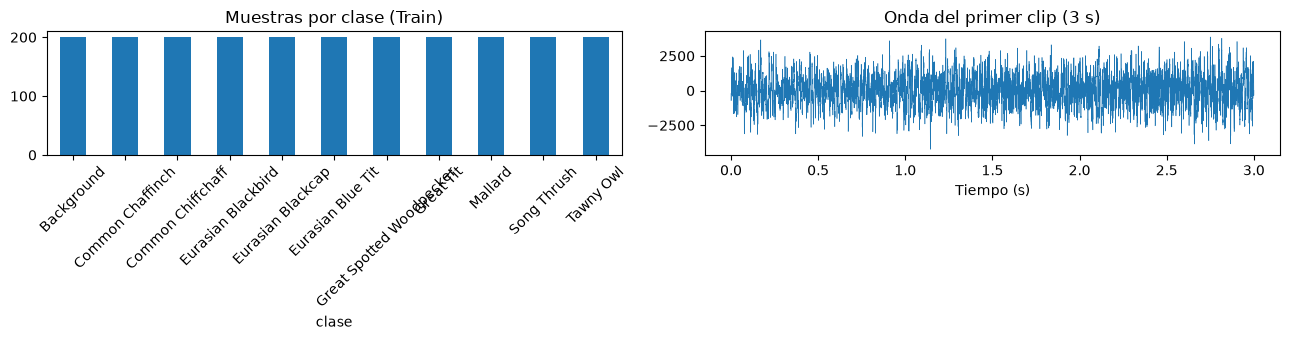

In [3]:
print(df.groupby(["split", "clase"]).size().to_string())
print()
sr0, w0 = wavfile.read(df["path"].iloc[0])
print(f"Tasa de muestreo: {sr0} Hz, Duración del primer clip: {len(w0) / sr0:.2f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
df[df["split"] == "train"]["clase"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="Muestras por clase (Train)")
axes[0].tick_params(axis="x", rotation=45)
t = np.arange(len(w0)) / sr0
axes[1].plot(t, w0, lw=0.4)
axes[1].set_title("Onda del primer clip (3 s)")
axes[1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.savefig(RES / "eda.png", bbox_inches="tight")
plt.show()

In [27]:
mfcc_transform = MFCC(sample_rate=SR, n_mfcc=N_MFCC,
                      melkwargs={"n_mels": 64, "n_fft": 1024})

def get_features(ruta):
    _, wav = wavfile.read(ruta)
    wave = torch.from_numpy(wav.astype(np.float32) / 32768.0)
    if wave.ndim == 1:
        wave = wave.unsqueeze(0)
    mfcc = mfcc_transform(wave)[0]
    stats = []
    for coef in mfcc:
        stats.append([coef.mean(), coef.std(), coef.min(), coef.max()])
    return np.asarray(stats, dtype=np.float32).ravel()

X = np.stack([get_features(p) for p in df["path"]])
y = df["codigo"].to_numpy(dtype=np.int64)
print("X:", X.shape, "| y:", y.shape)
print(X[0].reshape(26,4))

X: (2749, 104) | y: (2749,)
[[-102.35921      10.339766   -124.958595    -81.90322   ]
 [ 121.739296      4.1806927   108.1743      130.77068   ]
 [  -3.297023      7.1640377   -17.371155     11.69812   ]
 [  23.893194      3.5721521    15.071179     33.359013  ]
 [  -9.666825      3.956313    -20.183784      1.2039065 ]
 [   7.430854      3.7162156    -0.87558967   15.493043  ]
 [  -1.7896454     4.009531    -12.431056      8.970705  ]
 [   7.4655123     3.4119828    -1.7020327    19.202164  ]
 [  -7.7234197     3.2079015   -16.40008       0.8178111 ]
 [  12.985511      3.8598204     2.4679928    23.753578  ]
 [  -1.6483887     3.3932242   -10.143275     11.332661  ]
 [   7.7846837     3.165171      0.45487806   14.695187  ]
 [  -5.320538      3.4140716   -14.738283      3.4713318 ]
 [   5.247519      3.79171      -7.3451905    15.399699  ]
 [  -2.2862453     3.1843367    -9.942122      6.2158675 ]
 [   7.190283      3.0423944    -2.1402612    14.908924  ]
 [  -2.8257833     3.1009634

In [5]:
idx_train = np.where(df["split"] == "train")[0]
idx_test = np.where(df["split"] == "test")[0]
X_tr, X_te = X[idx_train], X[idx_test]
y_tr, y_te = y[idx_train], y[idx_test]

media = X_tr.mean(axis=0)
desv = X_tr.std(axis=0)
X_tr = (X_tr - media) / desv
X_te = (X_te - media) / desv

Xtrain, Xval, ytrain, yval = train_test_split(
    X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=SEED)
print(f"train: {Xtrain.shape}, val: {Xval.shape}, test: {X_te.shape}")

train: (1760, 104), val: (440, 104), test: (549, 104)


In [6]:
class DatasetAudio(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).long()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]

def creat_dataloaders(batch_size=BATCH):
    train_dl = DataLoader(DatasetAudio(Xtrain, ytrain), batch_size=batch_size, shuffle=True)
    val_dl = DataLoader(DatasetAudio(Xval, yval), batch_size=batch_size)
    test_dl = DataLoader(DatasetAudio(X_te, y_te), batch_size=batch_size)
    return train_dl, val_dl, test_dl

In [7]:
def build_model(d_in, h1, h2, d_out, dropout):
    return nn.Sequential(
        nn.Linear(d_in, h1), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(h2, d_out),
    )

model = build_model(X.shape[1], 128, 64, len(clases), 0.3).to(device)
out = model(torch.randn((64, X.shape[1])).to(device))
print("Entrada: (64,", X.shape[1], ") -> Salida:", tuple(out.shape))

Entrada: (64, 104 ) -> Salida: (64, 11)


In [8]:
criterion = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
train_dl, val_dl, test_dl = creat_dataloaders()
xb, yb = next(iter(train_dl))
xb, yb = xb.to(device), yb.to(device)

opt.zero_grad()
loss_uno = criterion(model(xb[:1]), yb[:1])
loss_uno.backward()
opt.step()

opt.zero_grad()
loss_batch = criterion(model(xb), yb)
loss_batch.backward()
opt.step()

print("Costo 1 muestra:", round(loss_uno.item(), 4))
print("Costo 1 batch:", round(loss_batch.item(), 4))

Costo 1 muestra: 2.389
Costo 1 batch: 2.3579


In [9]:
def fit(model, tl, vl, epochs=EPOCHS, lr=LR, wd=WD, patience=PATIENCE):
    criterion = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=3)
    hist = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
    best = {"acc": -1.0, "epoch": 0, "state": None}
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        s_loss, s_hit, n = 0.0, 0, 0
        for xb, yb in tl:
            xb, yb = xb.to(device), yb.to(device)
            loss = criterion(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            s_loss += loss.item() * len(xb)
            s_hit += (model(xb).argmax(dim=1) == yb).sum().item()
            n += len(xb)
        hist["loss"].append(s_loss / n)
        hist["acc"].append(s_hit / n)
        model.eval()
        with torch.no_grad():
            v_loss, v_hit, vn = 0.0, 0, 0
            for xb, yb in vl:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                v_loss += criterion(logits, yb).item() * len(xb)
                v_hit += (logits.argmax(dim=1) == yb).sum().item()
                vn += len(xb)
        hist["val_loss"].append(v_loss / vn)
        hist["val_acc"].append(v_hit / vn)
        scheduler.step(hist["val_loss"][-1])
        if hist["val_acc"][-1] > best["acc"]:
            best = {"acc": hist["val_acc"][-1], "epoch": epoch,
                     "state": {k: v.clone() for k, v in model.state_dict().items()}}
        if epoch - best["epoch"] >= patience:
            print(f"ES {epoch} , best {best['epoch']}")
            break
    model.load_state_dict(best["state"])
    return model, hist, best, time.time() - t0

def evaluar(model, dl):
    model.eval()
    y_true, y_pred, proba = [], [], []
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            prob = torch.softmax(logits, dim=-1)
            y_true += yb.tolist()
            y_pred += logits.argmax(dim=1).tolist()
            proba += prob.cpu().tolist()
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    proba = np.asarray(proba)
    met = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro"),
        "recall_macro": recall_score(y_true, y_pred, average="macro"),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "roc_auc_macro": roc_auc_score(y_true, proba, multi_class="ovr", average="macro"),
    }
    return met, y_true, y_pred, proba

def plotear(hist, titulo, ax, metric="loss"):
    ax.plot(hist[metric], label="train")
    ax.plot(hist["val_" + metric], label="val")
    ax.set_title(titulo)
    ax.set_xlabel("epoch")
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(alpha=0.3)

ES 19 , best 9
ES 23 , best 13
ES 30 , best 20
ES 38 , best 28
ES 20 , best 10
ES 25 , best 15
ES 36 , best 26
ES 39 , best 29
ES 19 , best 9
ES 17 , best 7
ES 36 , best 26
ES 21 , best 11


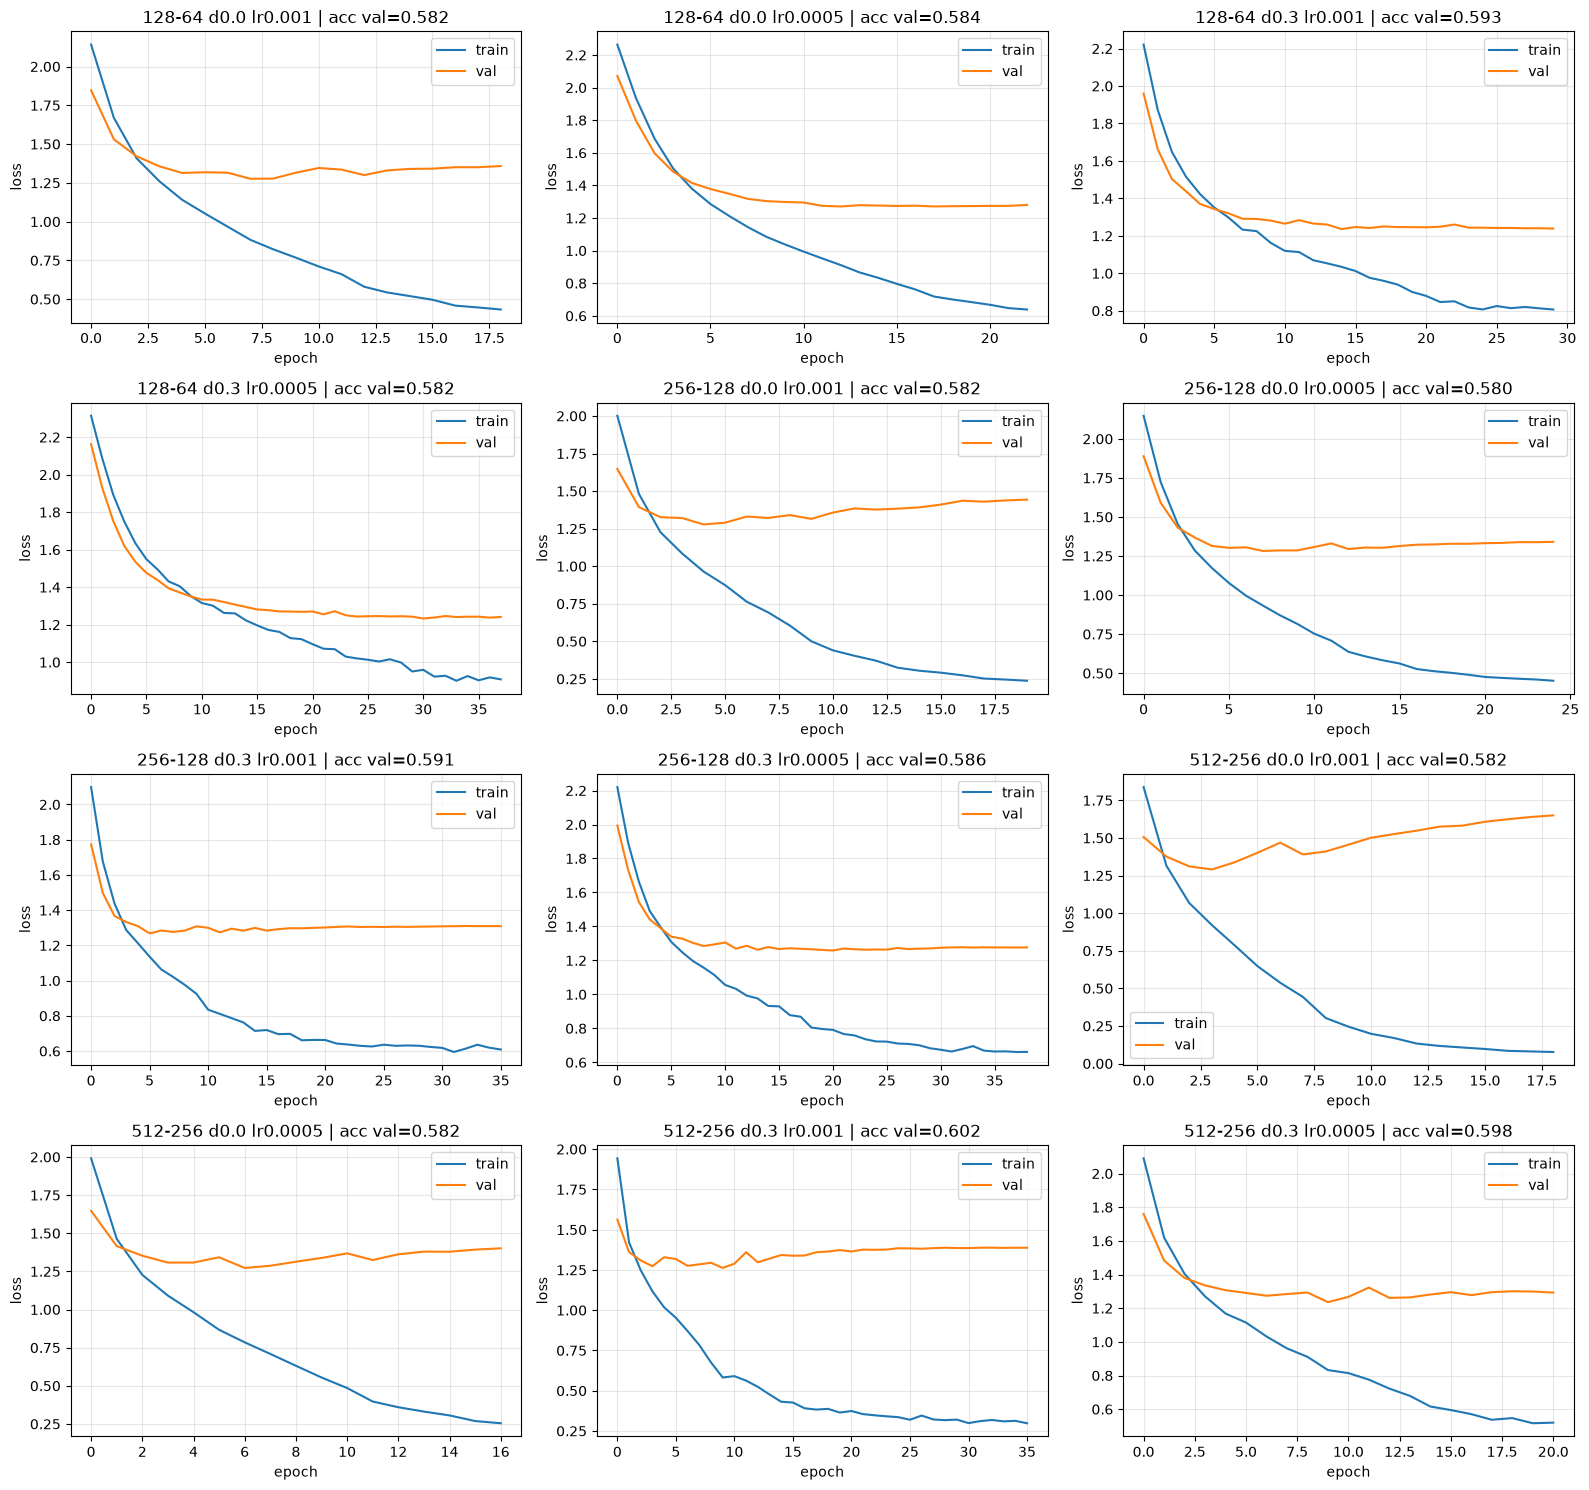

     h1   h2  dropout      lr  best_epoch  tiempo_s  val_acc  val_f1  \
6   256  128      0.3  0.0010          26       5.7   0.5909  0.5839   
10  512  256      0.3  0.0010          26       8.1   0.6023  0.6000   
7   256  128      0.3  0.0005          29       5.3   0.5864  0.5789   
11  512  256      0.3  0.0005          11       8.0   0.5977  0.5880   
8   512  256      0.0  0.0010           9       3.0   0.5818  0.5777   
5   256  128      0.0  0.0005          15       4.1   0.5795  0.5728   
9   512  256      0.0  0.0005           7       3.1   0.5818  0.5715   
4   256  128      0.0  0.0010          10       2.1   0.5818  0.5818   
0   128   64      0.0  0.0010           9       1.5   0.5818  0.5770   
2   128   64      0.3  0.0010          20       6.7   0.5932  0.5828   
3   128   64      0.3  0.0005          28       4.8   0.5818  0.5742   
1   128   64      0.0  0.0005          13       1.6   0.5841  0.5774   

    test_acc  test_f1  test_auc_ovr  
6     0.6084   0.6065    

In [10]:
grid = []
for (h1, h2) in [(128, 64), (256, 128), (512, 256)]:
    for dropout in [0.0, 0.3]:
        for lr in [1e-3, 5e-4]:
            grid.append({"h1": h1, "h2": h2, "dropout": dropout, "lr": lr})

filas = []
fig, axes = plt.subplots(4, 3, figsize=(16, 15))
for i, cfg in enumerate(grid):
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    tl, vl, tst = creat_dataloaders()
    m = build_model(X.shape[1], cfg["h1"], cfg["h2"], len(clases), cfg["dropout"]).to(device)
    m, hist, best, tiempo = fit(m, tl, vl, lr=cfg["lr"])
    met_val, *_ = evaluar(m, vl)
    met_te, *_ = evaluar(m, tst)
    filas.append({
        "h1": cfg["h1"], "h2": cfg["h2"], "dropout": cfg["dropout"], "lr": cfg["lr"],
        "best_epoch": best["epoch"], "tiempo_s": round(tiempo, 1),
        "val_acc": round(met_val["accuracy"], 4), "val_f1": round(met_val["f1_macro"], 4),
        "test_acc": round(met_te["accuracy"], 4), "test_f1": round(met_te["f1_macro"], 4),
        "test_auc_ovr": round(met_te["roc_auc_macro"], 4),
    })
    ax = axes[i // 3, i % 3]
    plotear(hist, f"{cfg['h1']}-{cfg['h2']} d{cfg['dropout']} lr{cfg['lr']} | acc val={met_val['accuracy']:.3f}", ax, "loss")

plt.tight_layout()
plt.savefig(RES / "curvas_costo_sweep.png", bbox_inches="tight")
plt.show()

tabla = pd.DataFrame(filas).sort_values("test_acc", ascending=False)
tabla.to_csv(RES / "metricas_sweep.csv", index=False)
print(tabla)

Mejor:
 h1              256.0000
h2              128.0000
dropout           0.3000
lr                0.0010
best_epoch       26.0000
tiempo_s          5.7000
val_acc           0.5909
val_f1            0.5839
test_acc          0.6084
test_f1           0.6065
test_auc_ovr      0.9033
ES 30 , best 18
Train: 3.8 s, mejor epoch 18 , val_acc 0.5955


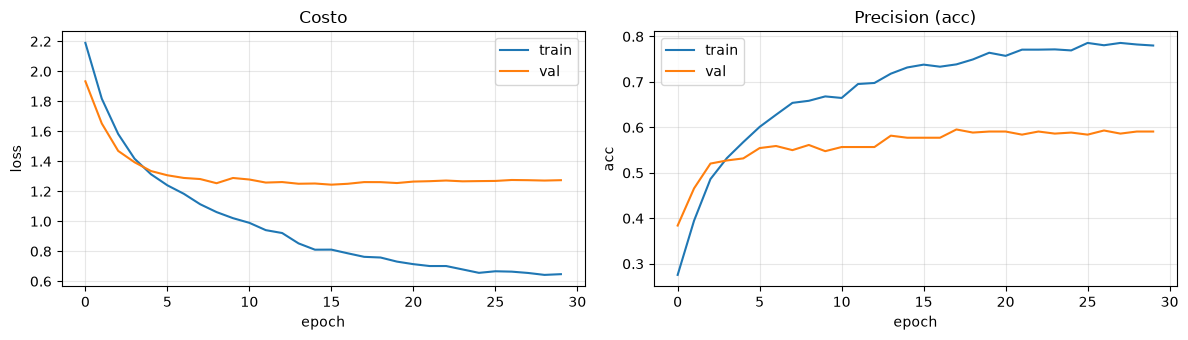

In [11]:
bst_cfg = tabla.iloc[0]
print("Mejor:\n", bst_cfg.to_string())

torch.manual_seed(SEED)
np.random.seed(SEED)
tl_f, vl_f, tst_f = creat_dataloaders(batch_size=64)
m_final = build_model(X.shape[1], int(bst_cfg["h1"]), int(bst_cfg["h2"]),
                      len(clases), float(bst_cfg["dropout"])).to(device)
m_final, hist_final, bst_final, time_f = fit(
    m_final, tl_f, vl_f, epochs=100, lr=float(bst_cfg["lr"]), patience=12)
torch.save(m_final.state_dict(), RES / "mejor_checkpoint.pt")
print(f"Train: {time_f:.1f} s, mejor epoch {bst_final['epoch']} , val_acc {bst_final['acc']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plotear(hist_final, "Costo", axes[0], "loss")
plotear(hist_final, "Precision (acc)", axes[1], "acc")
plt.tight_layout()
plt.savefig(RES / "curvas_final.png", bbox_inches="tight")
plt.show()

In [12]:
met_final, y_true, y_pred, proba = evaluar(m_final, tst_f)
print("Métricas")
for k, v in met_final.items():
    print(f"  {k:15s} {v:.4f}")
print()
print(classification_report(y_true, y_pred, target_names=clases))

Métricas
  accuracy        0.5883
  precision_macro 0.5885
  recall_macro    0.5881
  f1_macro        0.5869
  roc_auc_macro   0.9018

                          precision    recall  f1-score   support

              Background       1.00      0.98      0.99        50
        Common Chaffinch       0.47      0.56      0.51        50
       Common Chiffchaff       0.62      0.66      0.64        50
      Eurasian Blackbird       0.49      0.56      0.52        50
       Eurasian Blackcap       0.47      0.40      0.43        50
       Eurasian Blue Tit       0.46      0.44      0.45        50
Great Spotted Woodpecker       0.38      0.40      0.39        50
               Great Tit       0.50      0.43      0.46        49
                 Mallard       0.82      0.82      0.82        50
             Song Thrush       0.49      0.42      0.45        50
               Tawny Owl       0.78      0.80      0.79        50

                accuracy                           0.59       549
     

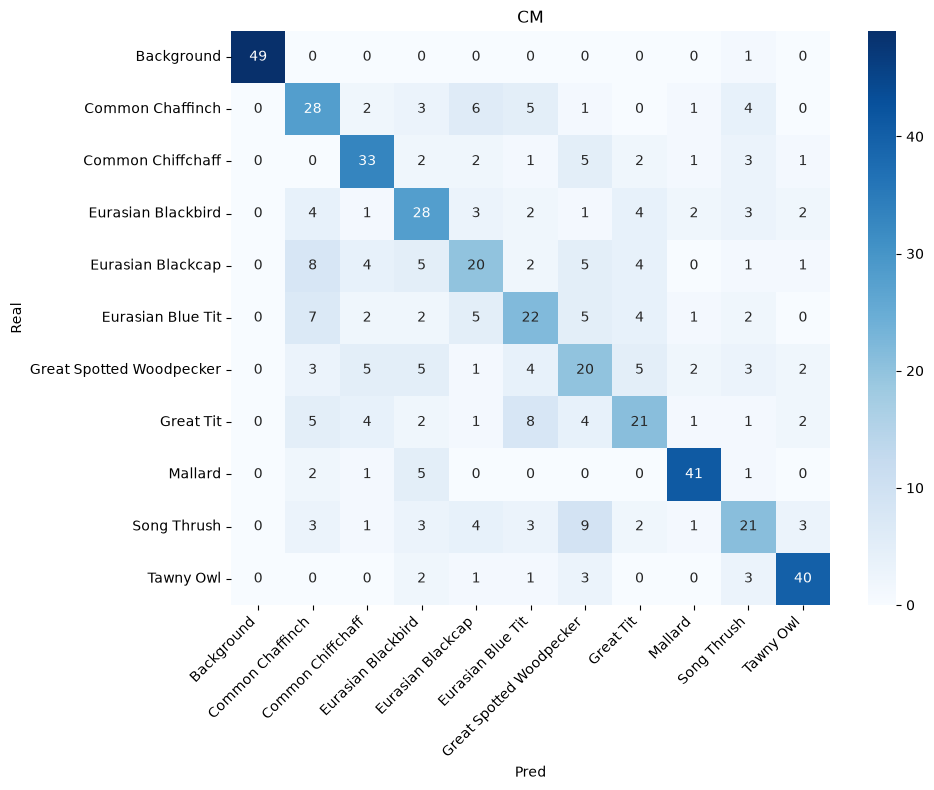

In [13]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=clases, yticklabels=clases)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Real")
plt.xlabel("Pred")
plt.title("CM")
plt.tight_layout()
plt.savefig(RES / "matriz_confusion.png", bbox_inches="tight")
plt.show()

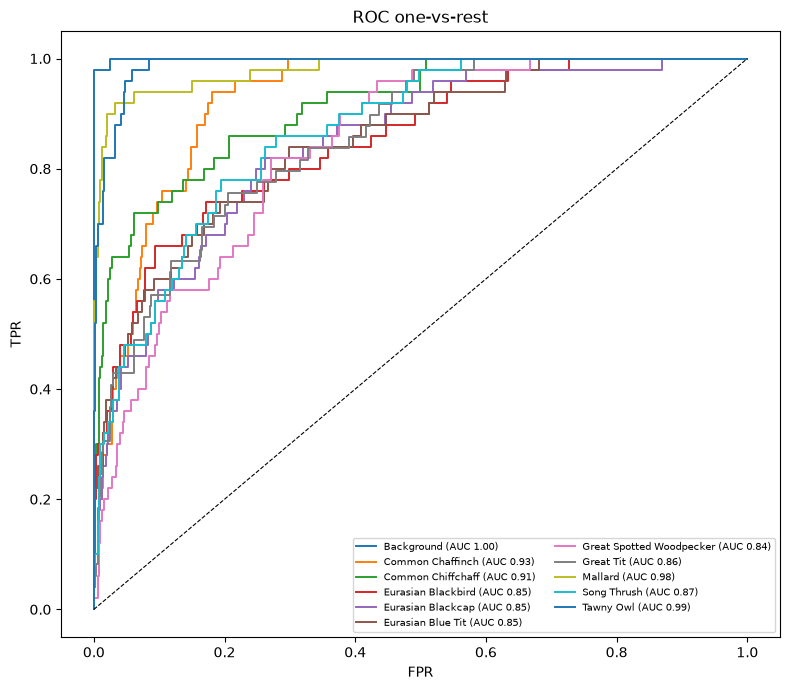

In [14]:
plt.figure(figsize=(8, 7))
for i, cl in enumerate(clases):
    binario = (y_true == i).astype(int)
    fpr, tpr, _ = roc_curve(binario, proba[:, i])
    plt.plot(fpr, tpr, lw=1.4,
             label=f"{cl} (AUC {roc_auc_score(binario, proba[:, i]):.2f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC one-vs-rest")
plt.legend(fontsize=7, ncol=2, loc="lower right")
plt.tight_layout()
plt.savefig(RES / "roc_auc.png", bbox_inches="tight")
plt.show()

In [25]:
pred_df = pd.DataFrame({
    "archivo": df.loc[idx_test, "path"].values,
    "real": [clases[c] for c in y_true],
    "pred": [clases[c] for c in y_pred],
    "acierto": y_true == y_pred,
})
pred_df.to_csv(RES / "predicciones.csv", index=False)
print(f"Predicciones {pred_df.shape[0]} filas, aciertos: {pred_df['acierto'].mean():.2%}")
print(pred_df.iloc[4*50:4*50 + 50])

Predicciones 549 filas, aciertos: 58.83%
                                               archivo               real  \
200  Validation/Eurasian Blackcap/BioDCASE2026_Tiny...  Eurasian Blackcap   
201  Validation/Eurasian Blackcap/BioDCASE2026_Tiny...  Eurasian Blackcap   
202  Validation/Eurasian Blackcap/BioDCASE2026_Tiny...  Eurasian Blackcap   
203  Validation/Eurasian Blackcap/BioDCASE2026_Tiny...  Eurasian Blackcap   
204  Validation/Eurasian Blackcap/BioDCASE2026_Tiny...  Eurasian Blackcap   
205  Validation/Eurasian Blackcap/BioDCASE2026_Tiny...  Eurasian Blackcap   
206  Validation/Eurasian Blackcap/BioDCASE2026_Tiny...  Eurasian Blackcap   
207  Validation/Eurasian Blackcap/BioDCASE2026_Tiny...  Eurasian Blackcap   
208  Validation/Eurasian Blackcap/BioDCASE2026_Tiny...  Eurasian Blackcap   
209  Validation/Eurasian Blackcap/BioDCASE2026_Tiny...  Eurasian Blackcap   
210  Validation/Eurasian Blackcap/BioDCASE2026_Tiny...  Eurasian Blackcap   
211  Validation/Eurasian Blackcap/B